# Combined DAS, Seismometer, and Wind Figure

This notebook makes one vertically stacked figure with aligned time axes:

1. **Top row**: DAS spectrogram  
2. **Middle row**: Seismometer-based Welch spectrogram  
3. **Bottom row**: SWIFT wind speed and wind direction  

Inputs
- `outputs/das_spectrogram/das_spectrogram.npz`: from
  `scripts/das_spectrogram/main_spectrogram.py` (30-min blocks of the 5 Hz
  decimated files, every channel offset from the cable bend)
- `outputs/seismometer/welch_pca_results_N<k>.csv`: from
  `notebooks/seismometer/mainSwellDir_seism_Welch.ipynb`
- `data/SWIFT19_telemetry.nc`: SWIFT buoy wind

The main plotting axes are created from one `GridSpec`, and all rows share the same x-axis. This keeps the x-axis limits, tick positions, and panel widths aligned.


In [1]:
from __future__ import annotations

from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from das_tools.utils import proj_path

In [2]:
# ============================================================
# User settings
# ============================================================

# Time limits used by all rows
START_TIME = pd.Timestamp("2025-04-24 12:00:00")
END_TIME   = pd.Timestamp("2025-05-08 00:00:00")

# DAS spectrogram inputs
DAS_SPECTROGRAM = proj_path.output_dir("das_spectrogram", "das_spectrogram.npz")
# Channel offset from the cable bend. The decimated files keep -45..44
# (about -144 to +140 m); -45 is the end of leg 1.
DAS_CHANNEL_OFFSET = -45
# Blank blocks averaged from fewer 3-min segments than this (1 = keep all).
DAS_MIN_SEGMENTS = 1

# Seismometer Welch/PCA inputs
SENSOR_NO = 2
SEISMOMETER_ORI = [-8., -10., 12., 0., 0.]
SEIS_CSV = proj_path.output_dir("seismometer", f"welch_pca_results_N{SENSOR_NO}.csv")

# Choose which seismometer panel to draw:
#   "power"          -> Welch spectrogram, copied from plot_welch_time_frequency.ipynb cell 3
#   "azimuth"        -> azimuth scatter, copied from cell 2
#   "rectilinearity" -> rectilinearity scatter, copied from cell 4
SEIS_PANEL = "power"

# Wind input
WIND_NC = proj_path.data_dir("SWIFT19_telemetry.nc")

# Output
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUT_PDF = FIGURE_DIR / "combined_DAS_seismo_wind_3row.pdf"

# Figure style
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.size': 16,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

# Use a fixed locator so all rows have exactly the same major ticks.
# Change interval=1 for daily labels, interval=2 for every other day, etc.

DATE_LOCATOR = mdates.DayLocator(interval=1)
DATE_FORMATTER = mdates.DateFormatter("%-m/%-d")
DATE_MINOR_LOCATOR = mdates.HourLocator(interval=3)

In [3]:
# ============================================================
# DAS spectrogram
# ============================================================

def make_das_panel(npz_path: Path, channel_offset: int, min_segments: int):
    """Time edges, frequency edges and the normalized spectrogram P (freq, time).

    Blocks are laid on their full 30-min grid, so stretches without data, and
    blocks averaged from fewer than `min_segments` segments, stay blank.
    """
    with np.load(npz_path) as d:
        offsets = d["channel_offset"]
        if channel_offset not in offsets:
            raise ValueError(f"channel offset {channel_offset} not in {offsets[0]}..{offsets[-1]}")
        k = int(np.flatnonzero(offsets == channel_offset)[0])
        starts = pd.DatetimeIndex(pd.to_datetime(d["block_start"]))
        freq_hz = np.asarray(d["freq_hz"], dtype=float)
        psd_db = np.asarray(d["psd_db"][:, :, k], dtype=float)
        n_segments = d["n_segments"]
        block = pd.Timedelta(minutes=float(d["block_min"]))
        offset_m = float(d["offset_m"][k])

    keep = n_segments >= min_segments
    grid = pd.date_range(starts[0], starts[-1], freq=block)
    col = np.round((starts - grid[0]) / block).astype(int)
    power = np.full((len(freq_hz), len(grid)), np.nan)
    power[:, col[keep]] = psd_db[keep].T

    time_edges = mdates.date2num(grid.append(pd.DatetimeIndex([grid[-1] + block])).to_pydatetime())
    dfreq = np.median(np.diff(freq_hz))
    freq_edges = np.concatenate([[max(0.0, freq_hz[0] - dfreq / 2)],
                                 0.5 * (freq_hz[:-1] + freq_hz[1:]),
                                 [freq_hz[-1] + dfreq / 2]])

    panel = np.ma.masked_invalid(power)
    # Keep the same normalization convention as the original notebook.
    P = panel - np.nanmax(panel) + 25

    return time_edges, freq_edges, P, {"offset_m": offset_m, "n_segments": n_segments,
                                       "block_start": starts}

In [4]:
# ============================================================
# Plotting helper functions
# ============================================================

def plot_das_spectrogram(ax, cax, npz_path: Path, channel_offset: int, min_segments: int):
    time_edges, freq_edges, P, out = make_das_panel(npz_path, channel_offset, min_segments)

    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad(color="white")

    pcm = ax.pcolormesh(
        time_edges,
        freq_edges,
        P,
        shading="auto",
        vmin=-60,
        vmax=0,
        cmap=cmap,
        rasterized=True,
    )

    ax.set_ylabel("Frequency (Hz)")
    ax.set_title("Spectrogram (DAS)")
    ax.grid(True, alpha=0.5)

    cb = ax.figure.colorbar(pcm, cax=cax)
    cb.set_label("Normalized Power (dB)")

    return pcm, out


def plot_seismometer_panel(ax, cax, csv_file: Path, sensor_no: int, panel: str):
    df = pd.read_csv(csv_file)
    df["t_mid"] = pd.to_datetime(df["t_mid"])

    azimuth_corrected = (
        df["azimuth_deg_180"].to_numpy() + SEISMOMETER_ORI[sensor_no - 1]
    ) % 180.0

    if panel == "azimuth":
        values = azimuth_corrected
        cmap = "jet"
        clim = (0, 180)
        cbar_label = "Azimuth (deg)"
        title = "Azimuth (Seismometer)"

    elif panel == "rectilinearity":
        values = df["rectilinearity"].to_numpy()
        cmap = "viridis"
        clim = (0, 1)
        cbar_label = "Rectilinearity"
        title = "Rectilinearity (Seismometer)"

    elif panel == "power":
        P = 10 * np.log10(df["power_3c"].to_numpy())

        # Same artifact-suppression idea as the source notebook, but safer at edges.
        p_idx = int(np.nanargmax(P))
        i0 = max(0, p_idx - 200)
        i1 = min(len(P), p_idx + 200)
        P[i0:i1] = np.nanmin(P)

        values = P - np.nanmax(P)
        cmap = "inferno"
        clim = (-60, 0)
        cbar_label = "Normalized power (dB)"
        title = "Spectrogram (Seismometer N2)"

    else:
        raise ValueError(
            f"Unknown SEIS_PANEL={panel!r}. "
            "Use 'power', 'azimuth', or 'rectilinearity'."
        )

    sc = ax.scatter(
        df["t_mid"],
        df["freq_hz"],
        c=values,
        marker=".",
        s=6,
        cmap=cmap,
        rasterized=True,
    )
    sc.set_clim(*clim)

    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim([0, 1.0])
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    cb = ax.figure.colorbar(sc, cax=cax)
    cb.set_label(cbar_label)

    return sc, df


def plot_wind(ax, wind_nc: Path, start_time: pd.Timestamp, end_time: pd.Timestamp):
    ds = xr.open_dataset(wind_nc)
    ds_sel = ds.sel(time=slice(start_time, end_time))

    time = ds_sel["time"].values
    wind_speed = ds_sel["wind_speed"].values
    wind_dir = ds_sel["winddirR"].values

    # ------------------------------------------------------------
    # Create twin axis FIRST
    # ------------------------------------------------------------
    ax2 = ax.twinx()

    # ------------------------------------------------------------
    # ax = WIND DIRECTION --> RIGHT
    # ------------------------------------------------------------
    line2, = ax.plot(
        time,
        wind_dir,
        linewidth=2.0,
        color="0.35",
        label="Wind direction",
        linestyle=':'
    )

    ax.set_ylabel("Wind Direction (deg)", labelpad=12)
    ax.set_ylim(20, 90)
    ax.set_yticks(range(30,100,20))
    
    ax.yaxis.set_ticks_position("right")
    ax.yaxis.set_label_position("right")

    ax.tick_params(
        axis="y",
        which="both",
        left=False,
        labelleft=False,
        right=True,
        labelright=True,
    )

    # ------------------------------------------------------------
    # ax2 = WIND SPEED --> LEFT
    # ------------------------------------------------------------
    line1, = ax2.plot(
        time,
        wind_speed,
        linewidth=2.5,
        color="tab:blue",
        label="Wind speed",
    )

    ax2.set_ylabel(
        "Wind Speed (m/s)",
        color="tab:blue",
        labelpad=12,
        fontweight="bold",
    )
    ax2.set_ylim(0, 14)
    ax2.set_yticks(range(0, 15, 2))

    ax2.yaxis.set_ticks_position("left")
    ax2.yaxis.set_label_position("left")

    ax2.tick_params(
        axis="y",
        which="both",
        left=True,
        labelleft=True,
        right=False,
        labelright=False,
        labelcolor="tab:blue",
        width=1.2,
    )

    for label in ax2.get_yticklabels():
        label.set_fontweight("bold")

    # ------------------------------------------------------------
    # Spines
    # ------------------------------------------------------------
    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(True)

    ax2.spines["left"].set_visible(True)
    ax2.spines["right"].set_visible(False)

    # ------------------------------------------------------------
    # Make ax2 transparent so ax remains visible
    # ------------------------------------------------------------
    ax2.patch.set_visible(False)

    # ------------------------------------------------------------
    # X-axis grid belongs to ax
    # ------------------------------------------------------------
    ax.grid(True, axis="x", alpha=0.5)
    ax2.grid(True,alpha=0.5)

    ax.set_title("Wind speed and direction (SWIFT)")
    ax.legend(loc='upper left')
    return ax2, ds_sel, (line1, line2)


def apply_shared_time_axis(axes, start_time, end_time):
    start_dt = pd.Timestamp(start_time).to_pydatetime()
    end_dt = pd.Timestamp(end_time).to_pydatetime()

    for ax in axes:
        ax.set_xlim(start_dt, end_dt)
        ax.xaxis.set_major_locator(DATE_LOCATOR)
        ax.xaxis.set_major_formatter(DATE_FORMATTER)
        # Minor ticks: every 3 hours, no labels
        ax.xaxis.set_minor_locator(DATE_MINOR_LOCATOR)

        ax.grid(True, axis="x", which="major", alpha=0.5)
        ax.grid(True, axis="x", which="minor", alpha=0.25)

    # Hide x tick labels except bottom row.
    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)

    axes[-1].set_xlabel("Date (UTC), 2025")


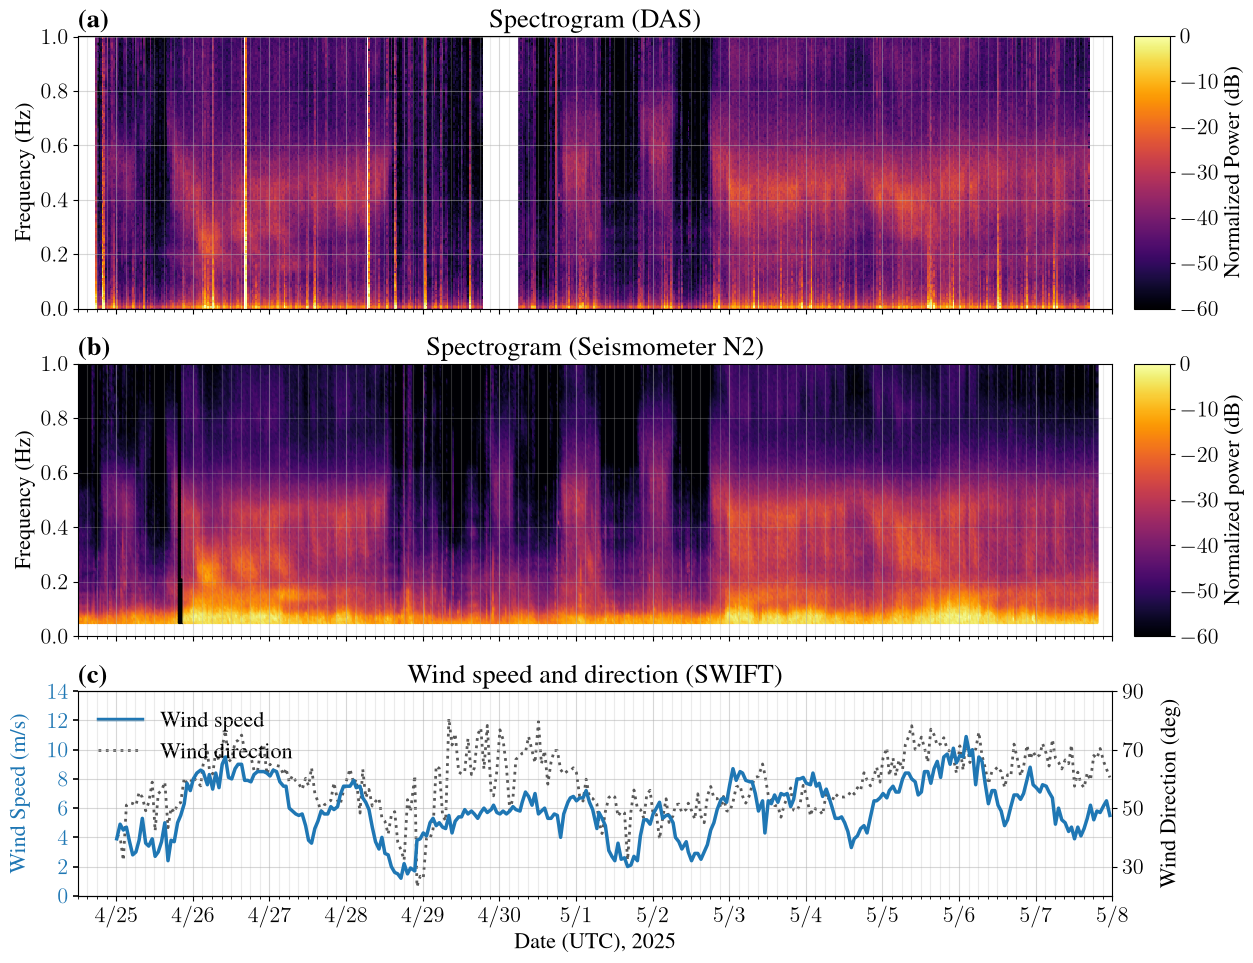

Saved: figures/combined_DAS_seismo_wind_3row.pdf


In [5]:
# ============================================================
# Build the combined 3-row figure
# ============================================================

fig = plt.figure(figsize=(13, 10), constrained_layout=False)

# Two columns: main data panels + colorbar column.
# The bottom-right cell is intentionally blank so all main axes have
# exactly the same width.
gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    width_ratios=[1.0, 0.035],
    height_ratios=[1.0, 1.0, 0.75],
    left=0.08,
    right=0.92,
    bottom=0.08,
    top=0.94,
    hspace=0.22,
    wspace=0.04,
)

ax_das = fig.add_subplot(gs[0, 0])
cax_das = fig.add_subplot(gs[0, 1])

ax_seis = fig.add_subplot(gs[1, 0], sharex=ax_das)
cax_seis = fig.add_subplot(gs[1, 1])

ax_wind = fig.add_subplot(gs[2, 0], sharex=ax_das)


cax_blank = fig.add_subplot(gs[2, 1])
cax_blank.axis("off")

pcm_das, das_data = plot_das_spectrogram(
    ax_das,
    cax_das,
    DAS_SPECTROGRAM,
    DAS_CHANNEL_OFFSET,
    DAS_MIN_SEGMENTS,
)

sc_seis, seis_df = plot_seismometer_panel(
    ax_seis,
    cax_seis,
    SEIS_CSV,
    SENSOR_NO,
    SEIS_PANEL,
)

ax_wind2, ds_wind, wind_handles = plot_wind(
    ax_wind,
    WIND_NC,
    START_TIME,
    END_TIME,
)
line_speed, line_dir = wind_handles

ax_wind.legend(
    [line_speed, line_dir],
    ["Wind speed", "Wind direction"],
    loc="upper left",
    frameon=False,
)

apply_shared_time_axis(
    [ax_das, ax_seis, ax_wind],
    START_TIME,
    END_TIME,
)

# Panel labels, left-aligned on the title line
for label, ax in zip(["(a)", "(b)", "(c)"], [ax_das, ax_seis, ax_wind]):
    ax.set_title(rf"\textbf{{{label}}}", loc="left")

# fig.suptitle(
#     "DAS spectrogram, seismometer spectrogram, and SWIFT wind",
#     y=1.0,
# )

fig.savefig(OUT_PDF, dpi=300)
plt.show()

print(f"Saved: {OUT_PDF}")
